# Implementations of Dimension Analysis Computational Methods

In [2]:
import matplotlib.pyplot as plt
import numpy as np

## Julia Set Generating Function

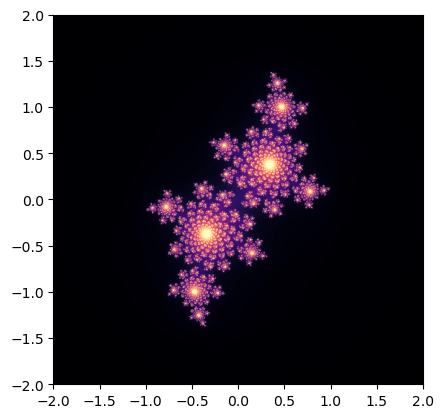

In [76]:
width, height = 1000, 1000
max_iters = 150
img = np.zeros((width, height))
def generate_julia_set(c):
    for x in range(width):
        for y in range(height):
            n = 0 # number of iterations
            i = -2.0 + x / width * 4.0
            j = -2.0 + y / height * 4.0
            z = complex(i,j)
            while abs(z) <= 2 and n < max_iters: 
                # while the point remains bounded
                z = z*z + c
                n+=1
            img[x,y] = n
    plt.imshow(img, cmap="magma", extent=(-2.0, 2.0, -2.0, 2.0))
    plt.savefig("julia_set.png")

generate_julia_set(-0.4 + 0.6j)

## Box-counting Dimension Computing Function

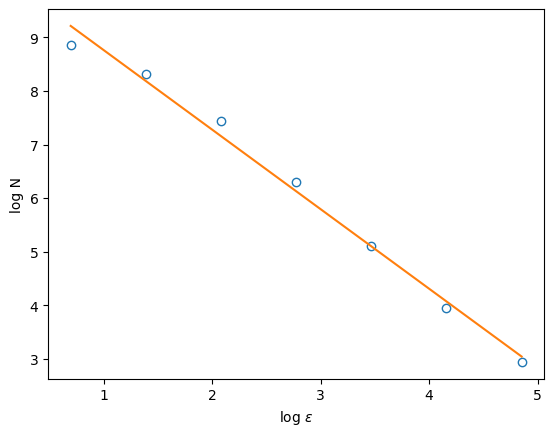

The Hausdorff dimension is 1.4828250911210525


In [77]:
# adapted from francesco turci on wordpress
def box_counting(z):

    n = 2**int(np.ceil(np.log2(max(z.shape))))
    #defining scales
    sizes = 2 ** np.arange(1, int(np.log2(n)) -2)

    #
    counts = []

    i, j = np.nonzero(z)

    for size in sizes:
        counts.append(len(np.unique(np.column_stack((i//size, j//size)), axis=0)))

    coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
    D = -coeffs[0]

    plt.plot(np.log(sizes), np.log(counts), 'o', mfc="none")
    plt.plot(np.log(sizes), np.polyval(coeffs, np.log(sizes)))
    plt.xlabel("log $\epsilon$")
    plt.ylabel("log N")
    plt.show()

    print(f"The Hausdorff dimension is {D}")

z = img >= max_iters

box_counting(z)